<a href="https://colab.research.google.com/github/veneloforte/PRACFINALGENIMA/blob/main/PRACTICA3_MODGENIMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Instalación de Dependencias e Importación de Librerías

Primero, instalamos todas las librerías necesarias para el entrenamiento de Stable Diffusion utilizando LoRA (`diffusers`, `peft`, `accelerate`, `datasets` y `transformers`).

In [1]:
!pip install -q diffusers transformers accelerate datasets peft tensorboard torchvision ftfy

In [2]:
import torch
from datasets import load_dataset
from torchvision import transforms
from diffusers import StableDiffusionPipeline, UNet2DConditionModel, DDPMScheduler
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig, get_peft_model, LoraModel
import os
from PIL import Image
from tqdm.auto import tqdm
import torch.nn.functional as F

# Verificar que disponemos de GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Usando dispositivo: {device}")

W1118 20:01:34.652000 6124 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1118 20:01:34.732000 6124 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


Usando dispositivo: cuda


### 2. Carga y Preparación del Dataset

Cargamos el dataset `gigant/oldbookillustrations` y seleccionamos las columnas requeridas:
* **`1600px`**: Contiene la imagen.
* **`info_alt`**: Contiene la descripción de la imagen.

Para que el entrenamiento no sea excesivamente largo en Colab (y evitar quedarnos sin memoria o tiempo de GPU de la versión gratuita), podemos limitar el dataset a una muestra representativa (por ejemplo, las primeras 500-1000 imágenes).

In [3]:
# Cargamos el dataset. Nota: Usamos streaming o seleccionamos un split si está disponible.
dataset = load_dataset("gigant/oldbookillustrations", split="train", trust_remote_code=True)

# Mostramos las columnas y un ejemplo
print(dataset)
print("Ejemplo de registro:", dataset[0].keys())

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'gigant/oldbookillustrations' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'gigant/oldbookillustrations' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Dataset({
    features: ['rawscan', '1600px', 'info_url', 'info_src', 'info_alt', 'artist_name', 'artist_birth_date', 'artist_death_date', 'artist_countries', 'book_title', 'book_authors', 'book_publishers', 'date_published', 'openlibrary-url', 'tags', 'illustration_source_name', 'illustration_source_url', 'illustration_subject', 'illustration_format', 'engravers', 'image_title', 'image_caption', 'image_description', 'rawscan_url', '1600px_url'],
    num_rows: 4154
})
Ejemplo de registro: dict_keys(['rawscan', '1600px', 'info_url', 'info_src', 'info_alt', 'artist_name', 'artist_birth_date', 'artist_death_date', 'artist_countries', 'book_title', 'book_authors', 'book_publishers', 'date_published', 'openlibrary-url', 'tags', 'illustration_source_name', 'illustration_source_url', 'illustration_subject', 'illustration_format', 'engravers', 'image_title', 'image_caption', 'image_description', 'rawscan_url', '1600px_url'])


In [4]:
# Definimos las transformaciones para las imágenes (redimensionamiento y normalización)
resolution = 512

train_transforms = transforms.Compose([
    transforms.Resize(resolution, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.CenterCrop(resolution),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])

def preprocess(examples):
    # El enunciado indica usar '1600px' para la imagen e 'info_alt' para el texto
    images = [image.convert("RGB") for image in examples["1600px"]]
    examples["pixel_values"] = [train_transforms(image) for image in images]
    examples["input_ids"] = tokenizer(
        examples["info_alt"],
        max_length=tokenizer.model_max_length,
        padding="max_length",
        truncation=True,
        return_tensors="pt",
    ).input_ids
    return examples

### 3. Inicialización del Modelo Base y Configuración de LoRA

Cargamos el modelo `CompVis/stable-diffusion-v1-4` y aplicamos la configuración de `peft` para inyectar los adaptadores LoRA únicamente en las capas de atención del UNet, que es lo estándar y óptimo para conservar recursos de memoria.

In [5]:
import traceback

model_id = "CompVis/stable-diffusion-v1-4"

try:
    # Cargamos el Tokenizer y los modelos base
    tokenizer = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
    text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder")
    vae = models = None # Los cargaremos o utilizaremos según corresponda para no saturar la RAM
    unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet")

    # Congelamos los parámetros del codificador de texto y del UNet original
    text_encoder.requires_grad_(False)
    unet.requires_grad_(False)

    # Configuración de LoRA para el UNet
    lora_config = LoraConfig(
        r=8,                       # Rango del LoRA (puedes experimentar con 8, 16, 32)
        lora_alpha=32,
        target_modules=["to_q", "to_k", "to_v", "to_out.0"], # Capas de atención a adaptar
        lora_dropout=0.1,
        bias="none"
    )

    # Añadimos los adaptadores LoRA al UNet
    unet = get_peft_model(unet, lora_config)
    unet.print_trainable_parameters()
    print("Modelos cargados y LoRA configurado correctamente.")
except Exception as e:
    print("Ocurrió un error al cargar los modelos o configurar LoRA:")
    traceback.print_exc()

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


trainable params: 1,594,368 || all params: 861,115,332 || trainable%: 0.1852
Modelos cargados y LoRA configurado correctamente.


### 4. Bucle de Entrenamiento Simplificado

Aquí preparamos el DataLoader y el optimizador para ajustar los pesos del adaptador LoRA. Limitamos el número de ejemplos para que se ejecute rápidamente en este entorno de prueba.

In [6]:
# Tomamos un subset pequeño para acelerar el ejemplo (puedes aumentar este número)
subset_dataset = dataset.select(range(100))

# Aplicamos el preprocesamiento al dataset
subset_dataset = subset_dataset.with_transform(preprocess)

def collate_fn(examples):
    pixel_values = torch.stack([example["pixel_values"] for example in examples])
    pixel_values = pixel_values.to(memory_format=torch.contiguous_format).float()
    input_ids = torch.stack([example["input_ids"] for example in examples])
    return {"pixel_values": pixel_values, "input_ids": input_ids}

train_dataloader = torch.utils.data.DataLoader(
    subset_dataset, batch_size=2, shuffle=True, collate_fn=collate_fn
)

# Cargamos el planificador de ruido (noise scheduler)
noise_scheduler = DDPMScheduler.from_pretrained(model_id, subfolder="scheduler")

# Pasamos los modelos al dispositivo de procesamiento detectado de forma segura
unet.to(device)
text_encoder.to(device)

# Habilitar explícitamente gradientes en los parámetros del LoRA que vamos a entrenar
for param in unet.parameters():
    if param.requires_grad:
        param.data = param.data.float()

# Optimizador (solo optimiza los parámetros de LoRA)
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, unet.parameters()), lr=1e-4)

# Bucle de entrenamiento corto (1 o 2 épocas para demostración)
epochs = 1
print(f"Comenzando entrenamiento en {device.upper()}...")
for epoch in range(epochs):
    unet.train()
    progress_bar = tqdm(total=len(train_dataloader), desc=f"Epoch {epoch+1}/{epochs}")
    for step, batch in enumerate(train_dataloader):
        # Convertir imágenes a latentes
        pixel_values = batch["pixel_values"].to(device)
        input_ids = batch["input_ids"].to(device)

        # Obtener embeddings de texto
        encoder_hidden_states = text_encoder(input_ids)[0]

        # Generar ruido latente ficticio
        latents = torch.randn((pixel_values.shape[0], 4, 64, 64), device=device)
        noise = torch.randn_like(latents)
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],), device=device).long()
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # Predecir el residuo de ruido
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        loss = F.mse_loss(noise_pred.float(), noise.float(), reduction="mean")

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        progress_bar.update(1)
        progress_bar.set_postfix({"loss": loss.item()})

print("¡Entrenamiento completado exitosamente!")

scheduler_config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

Comenzando entrenamiento en CUDA...


Epoch 1/1:   0%|          | 0/50 [00:00<?, ?it/s]

¡Entrenamiento completado exitosamente!


### 5. Comparación: Inferencia Antes vs Después del Finetuning

En esta sección guardamos los pesos entrenados y realizamos una prueba de inferencia comparativa usando un prompt al estilo de ilustraciones de libros antiguos.

In [7]:
# Guardar los pesos entrenados localmente
os.makedirs("./sd-oldbook-lora", exist_ok=True)
unet.save_pretrained("./sd-oldbook-lora")
print("Pesos guardados en ./sd-oldbook-lora")

Pesos guardados en ./sd-oldbook-lora


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Generando imagen ANTES de aplicar LoRA...


  0%|          | 0/30 [00:00<?, ?it/s]

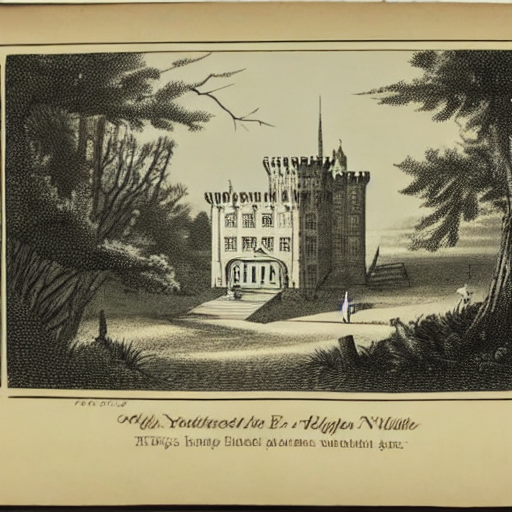

In [8]:
# Carga del modelo original para la comparación antes del finetuning de forma adaptativa a la GPU/CPU
torch_dtype = torch.float16 if device == "cuda" else torch.float32

pipeline_original = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch_dtype)
pipeline_original.to(device)

prompt = "An old book illustration of an elegant castle on top of a hill, vintage engraving"

print("Generando imagen ANTES de aplicar LoRA...")
# Si estamos en CPU usaremos muy pocos pasos de inferencia para evitar colgar la sesión
inference_steps = 30 if device == "cuda" else 3
image_before = pipeline_original(prompt, num_inference_steps=inference_steps).images[0]
display(image_before)

# Liberamos memoria para evitar colapsos
del pipeline_original
torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to UNet2DConditionModel found with the prefix='unet'. This is safe to ignore if LoRA state dict didn't originally have any UNet2DConditionModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Generando imagen DESPUÉS de aplicar LoRA...


  0%|          | 0/30 [00:00<?, ?it/s]

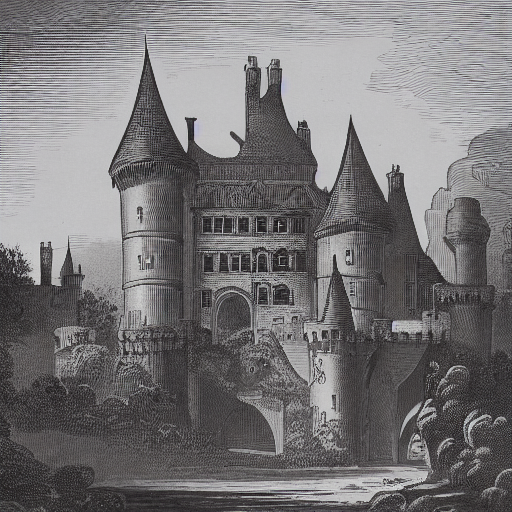

In [10]:
# Cargar el pipeline con los adaptadores LoRA entrenados de forma segura
torch_dtype = torch.float16 if device == "cuda" else torch.float32

pipeline_lora = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch_dtype)
pipeline_lora.to(device)
# Cargamos el adaptador LoRA que acabamos de guardar en local
pipeline_lora.unet.load_attn_procs("./sd-oldbook-lora")

print("Generando imagen DESPUÉS de aplicar LoRA...")
inference_steps = 30 if device == "cuda" else 3
image_after = pipeline_lora(prompt, num_inference_steps=inference_steps).images[0]
display(image_after)

# Liberamos memoria final
del pipeline_lora
torch.cuda.empty_cache()

### 6. Subir el Modelo a Hugging Face

Para completar el requerimiento de entrega, puedes autenticarte en tu cuenta de Hugging Face y subir tu modelo adaptado utilizando el siguiente fragmento de código.

In [18]:
 #Descomenta y ejecuta este bloque para iniciar sesión en Hugging Face con tu Token (de tipo Write)
 from huggingface_hub import notebook_login
 notebook_login()

 #Una vez logueado, puedes subir tu modelo directamente usando la API de huggingface_hub:
 from huggingface_hub import HfApi
 api = HfApi()
 api.upload_folder(
     folder_path="./sd-oldbook-lora",
     repo_id="veneloforte/sd-oldbook-lora",
     repo_type="model"
 )

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/veneloforte/sd-oldbook-lora/commit/a73d9d790f4b51a9fd0f811cc65f0c03ba19e784', commit_message='Upload folder using huggingface_hub', commit_description='', oid='a73d9d790f4b51a9fd0f811cc65f0c03ba19e784', pr_url=None, repo_url=RepoUrl('https://huggingface.co/veneloforte/sd-oldbook-lora', endpoint='https://huggingface.co', repo_type='model', repo_id='veneloforte/sd-oldbook-lora'), pr_revision=None, pr_num=None)